# Attention Model for TSP: Paper Reproduction

**Paper:** *Attention, Learn to Solve Routing Problems!* (Kool, van Hoof, Welling, 2019)

**Scope:** Reimplementation of the Attention Model from the article on the TSP. Using PyTorch Geometric.

## Setup

In [1]:
import copy
import time
from collections import OrderedDict
from typing import NamedTuple

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import stats
from torch_geometric.data import Batch, Data
from torch_geometric.nn import summary
from torch_geometric.nn.conv import TransformerConv
from torch_geometric.nn.pool import global_mean_pool
from tqdm.auto import tqdm

from core.problems.tsp import TSPBatchSampler, TSPConfig, TSPInstance

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


In [8]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Data

> For all TSP instances, the $n$ node locations are sampled uniformly at random in the unit square.

In [10]:
sampler = TSPBatchSampler(
    TSPConfig(
        num_locations=20,
        min_coordinate=0.0,
        max_coordinate=1.0,
        distribution_of_locations="uniform",
    ),
)
example_batch_size = 42
example_tsp_batch = sampler(example_batch_size)

print("TSP batch shape:", example_tsp_batch.shape)  # (batch_size, num_locations, 2)

print("Example TSP instance (first in batch):")
print(example_tsp_batch[0][0])

TSP batch shape: torch.Size([42, 20, 2])
Example TSP instance (first in batch):
tensor([0.2673, 0.8725])


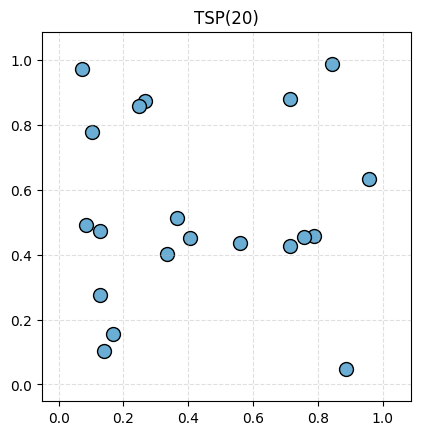

In [14]:
example_tsp_instance = TSPInstance.from_tensor(example_tsp_batch[0])
example_tsp_instance.visualize()
plt.show()

## Model Architecture

### Encoder

The encoder produces embeddings of all input nodes.

The following modules are the sublayers of the encoder.

In [18]:
class FeedForward(nn.Module):
    def __init__(self, model_hidden_dim: int, d_ff: int = 512) -> None:
        """
        Args:
            model_hidden_dim: The dimension denoted as $h$ in the paper.
            d_ff: The dimension of the hidden layer in the feedforward network. Equal to 512 in the paper.
        """
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(model_hidden_dim, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, model_hidden_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


class AttentionLayer(nn.Module):
    def __init__(self, d_h: int, num_heads: int = 8, d_ff: int = 512) -> None:
        super().__init__()
        assert d_h % num_heads == 0

        self.MHA = TransformerConv(
            in_channels=d_h,
            out_channels=d_h // num_heads,
            heads=num_heads,
            concat=True,
            dropout=0.0,
            bias=True,
        )
        self.BN1 = nn.BatchNorm1d(d_h)
        self.FF = FeedForward(d_h, d_ff)
        self.BN2 = nn.BatchNorm1d(d_h)

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor) -> torch.Tensor:
        # MHA sublayer (Eq. 2)
        x = self.BN1(x + self.MHA(x, edge_index))

        # FF sublayer (Eq. 3)
        x = self.BN2(x + self.FF(x))

        return x

In [19]:
class EncoderOutput(NamedTuple):
    h_nodes: torch.Tensor
    h_graph: torch.Tensor


class Encoder(nn.Module):
    def __init__(
        self,
        d_x: int = 2,
        d_h: int = 128,
        num_heads: int = 8,
        num_layers: int = 3,
        d_ff: int = 512,
    ) -> None:
        """
        Args:
            d_x: input feature dimensionality (2 for TSP: x, y coordinates)
            d_h: hidden embedding dimensionality (paper: 128)
            num_heads: attention heads (paper: 8)
            num_layers: number of attention layers N (paper: 3)
            d_ff: FF hidden dimensionality (paper: 512)
        """
        super().__init__()

        # Learned linear projection: h_i^(0) = W^x * x_i + b^x
        self.input_projection = nn.Linear(d_x, d_h)

        # N attention layers
        self.layers = nn.ModuleList(
            [AttentionLayer(d_h, num_heads, d_ff) for _ in range(num_layers)]
        )

    def forward(self, x, *, batch, edge_index) -> EncoderOutput:
        """
        Args:
            x: (total_nodes, d_x)
            batch: (total_nodes,)
            edge_index: (2, total_edges)

        Returns:
            h_nodes: (total_nodes, d_model)
            h_graph: (batch_size, d_model)
        """

        # Initial projection
        h = self.input_projection(x)  # (total_nodes, d_h)

        for layer in self.layers:
            h = layer(h, edge_index)

        # Graph-level embedding: mean of node embeddings per graph
        h_graph = global_mean_pool(h, batch)  # (B, d_h)

        return EncoderOutput(h, h_graph)

In [22]:
def make_complete_graph(x: torch.Tensor, self_connections: bool = True) -> Data:
    """Create a fully-connected PyG Data object for a single instance."""
    n = x.size(0)
    idx = torch.arange(n)
    src = idx.repeat_interleave(n)
    dst = idx.repeat(n)
    if not self_connections:
        mask = src != dst
        src = src[mask]
        dst = dst[mask]
    edge_index = torch.stack([src, dst], dim=0).to(x.device)
    return Data(x=x, edge_index=edge_index)


graphs = [
    make_complete_graph(torch.rand(10, 2)),
    make_complete_graph(torch.rand(12, 2)),
]

for graph in graphs:
    print(graph.edge_index)
    print(graph.num_edges)
    assert graph.num_edges == graph.num_nodes**2

batch = Batch.from_data_list(graphs)

print(f"Batch has {batch.num_graphs} graphs, {batch.num_nodes} nodes, {batch.num_edges} edges")
print(batch["batch"].shape)
print(batch["batch"])
print(batch["x"].shape)
print(batch["edge_index"].shape)

encoder = Encoder(d_x=2, d_h=128, num_heads=8, num_layers=3, d_ff=512)
h_nodes, h_graph = encoder(batch["x"], batch=batch["batch"], edge_index=batch["edge_index"])

print("Node embeddings shape:", h_nodes.shape)  # (total_nodes, d_h)
print("Graph embeddings shape:", h_graph.shape)  # (batch_size, d_h)

tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2,
         2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4,
         4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 7, 7,
         7, 7, 7, 7, 7, 7, 7, 7, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 9, 9, 9, 9, 9,
         9, 9, 9, 9],
        [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3,
         4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7,
         8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1,
         2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5,
         6, 7, 8, 9]])
100
tensor([[ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,  1,
          1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
          3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  4,  4,  4,  4,  4,  4,
          4,  4,  4,  4,  4,  4,  5,  5,  5,  5,  5,  5,  5,

In [23]:
print(summary(encoder, batch["x"], batch=batch["batch"], edge_index=batch["edge_index"]))

+----------------------------------+---------------------+---------------------+----------+
| Layer                            | Input Shape         | Output Shape        | #Param   |
|----------------------------------+---------------------+---------------------+----------|
| Encoder                          | [22, 2]             | [22, 128], [2, 128] | 595,200  |
| ├─(input_projection)Linear       | [22, 2]             | [22, 128]           | 384      |
| ├─(layers)ModuleList             | --                  | --                  | 594,816  |
| │    └─(0)AttentionLayer         | [22, 128], [2, 244] | [22, 128]           | 198,272  |
| │    │    └─(MHA)TransformerConv | [22, 128], [2, 244] | [22, 128]           | 66,048   |
| │    │    └─(BN1)BatchNorm1d     | [22, 128]           | [22, 128]           | 256      |
| │    │    └─(FF)FeedForward      | [22, 128]           | [22, 128]           | 131,712  |
| │    │    └─(BN2)BatchNorm1d     | [22, 128]           | [22, 128]           |

### Decoder

The decoder produces the solution as the sequence of input nodes, one node at a time.

In [24]:
class SingleHeadScorer(nn.Module):
    def __init__(self, d_h: int = 128, C: float = 10.0) -> None:
        super().__init__()
        self.scale = d_h**0.5
        self.C = C
        self.W_Q = nn.Linear(d_h, d_h, bias=False)
        self.W_K = nn.Linear(d_h, d_h, bias=False)

    def forward(self, h_c, h_nodes, mask) -> torch.Tensor:
        """
        Args:
            h_c: (batch, d_model)
            h_nodes: (batch, n, d_model)
            mask: (batch, n) bool
        Returns:
            log_p: (batch, n)
        """
        Q = self.W_Q(h_c).unsqueeze(1)  # (batch, 1, d_model)
        K = self.W_K(h_nodes)  # (batch, n, d_model)
        u = torch.matmul(Q, K.transpose(-2, -1)).squeeze(1) / self.scale  # (batch, n)
        u = self.C * torch.tanh(u)
        u = u.masked_fill(mask, float("-inf"))
        return F.log_softmax(u, dim=-1)

In the paper, the projection from the context node embedding (concatenation of graph embedding, last node, first node embeddings, of the dimensionality of $3*d_h$) to the $d_h$ is done inside the transformation by the query weight matrix, $W^Q$.

Here, I make it explicit as a separate linear layer, which allows to use PyTorch's built-in `MultiheadAttention` module for this step.

In [25]:
class Decoder(nn.Module):
    def __init__(self, d_h: int = 128, num_heads: int = 8, C: float = 10.0) -> None:
        super().__init__()
        self.d_h = d_h
        self.C = C

        self.v_l = nn.Parameter(torch.zeros(d_h))
        self.v_f = nn.Parameter(torch.zeros(d_h))

        # MODIFICATION: Project 3*d_model context down to d_model upfront
        self.context_projection = nn.Linear(3 * d_h, d_h, bias=False)

        self.mha = nn.MultiheadAttention(
            embed_dim=d_h,
            num_heads=num_heads,
            batch_first=True,
            bias=False,
        )
        self.final_scorer = SingleHeadScorer(d_h, C)

    def forward(self, h_nodes, h_graph, tour_idx) -> torch.Tensor:
        batch_size, n, _ = h_nodes.shape

        # Initial context embeddings for first and last node in the tour
        if len(tour_idx) == 0:
            h_last = self.v_l.expand(batch_size, -1)
            h_first = self.v_f.expand(batch_size, -1)
        else:
            h_first = h_nodes[torch.arange(batch_size), tour_idx[0]]
            h_last = h_nodes[torch.arange(batch_size), tour_idx[-1]]

        # Initial context embedding
        h_c = torch.cat([h_graph, h_last, h_first], dim=-1)

        # Project context to d_h
        h_c = self.context_projection(h_c)

        # Mask nodes that cannot be visited
        mask = torch.zeros(batch_size, n, dtype=torch.bool, device=h_nodes.device)
        for t_idx in tour_idx:
            mask[torch.arange(batch_size), t_idx] = True

        # MHA: context node attends over all unmasked nodes
        h_c, _ = self.mha(
            query=h_c.unsqueeze(1),
            key=h_nodes,
            value=h_nodes,
            key_padding_mask=mask,
        )
        h_c = h_c.squeeze(1)  # (batch, d_model)

        # Final single-head layer
        log_p = self.final_scorer(h_c, h_nodes, mask)
        return log_p

In [27]:
example_batch_size, n, d_h = 2, 4, 128

h_nodes = torch.randn(example_batch_size, n, d_h)
h_graph = torch.randn(example_batch_size, d_h)
decoder = Decoder(d_h=128, num_heads=8)

tour = []
log_probs = []

print("Decoding steps:")
for t in range(n):
    log_p = decoder(h_nodes, h_graph, tour_idx=tour)
    selected = log_p.argmax(dim=-1)  # greedy
    log_probs.append(log_p[torch.arange(example_batch_size), selected])
    tour.append(selected)
    print(f"t={t + 1} chosen: {selected.tolist()}")

Decoding steps:
t=1 chosen: [1, 1]
t=2 chosen: [3, 0]
t=3 chosen: [0, 2]
t=4 chosen: [2, 3]


In [28]:
print(summary(decoder, h_nodes, h_graph, tour))

+--------------------------------------------------+-------------------------------+------------------------+----------+
| Layer                                            | Input Shape                   | Output Shape           | #Param   |
|--------------------------------------------------+-------------------------------+------------------------+----------|
| Decoder                                          | [2, 4, 128], [2, 128]         | [2, 4]                 | 147,712  |
| ├─(context_projection)Linear                     | [2, 384]                      | [2, 128]               | 49,152   |
| ├─(mha)MultiheadAttention                        |                               | [2, 1, 128], [2, 1, 4] | 65,536   |
| │    └─(out_proj)NonDynamicallyQuantizableLinear | --                            | --                     | 16,384   |
| ├─(final_scorer)SingleHeadScorer                 | [2, 128], [2, 4, 128], [2, 4] | [2, 4]                 | 32,768   |
| │    └─(W_Q)Linear            

### Attention Model

As a useful indicator during training, I use the entropy of the node selection distribution at each decoding step.

**Entropy**

$$H(p) = -\sum_{i=1}^{k} p_i \log p_i$$

$$H_\texttt{max} (p) = \log k$$

$$H_\text{norm}(p) = \frac{H(p)}{H_\texttt{max} (p)}$$

$$k = \text{number of unmasked nodes}$$

In [29]:
class EntropyResult(NamedTuple):
    entropy: torch.Tensor
    entropy_norm: torch.Tensor
    entropy_max: torch.Tensor


def entropy(log_p: torch.Tensor) -> EntropyResult:
    """
    Compute entropy of the node selection distribution at a single decoding step.

    Ranges from 0 (always picks the same node) to log(k) where k is the number
    of unmasked nodes.
    """
    p = log_p.exp()
    H = -(p * log_p).nansum(dim=-1)  # (batch,)
    k = torch.isfinite(log_p).sum(dim=-1)
    H_max = torch.log(k.float())
    H_norm = H / H_max.clamp(min=1e-8)
    return EntropyResult(entropy=H, entropy_norm=H_norm, entropy_max=H_max)

In [ ]:
class RolloutResult(NamedTuple):
    tour: torch.Tensor
    log_p: torch.Tensor
    entropy: float | None
    entropy_norm: float | None

In [31]:
class AttentionModel(nn.Module):
    def __init__(self, d_x: int = 2, d_h: int = 128, num_heads: int = 8, num_layers: int = 3):
        super().__init__()
        self.encoder = Encoder(d_x, d_h, num_heads, num_layers)
        self.decoder = Decoder(d_h, num_heads)

    def forward(self, instances: torch.Tensor, *, greedy: bool = False) -> RolloutResult:
        """
        Args:
            instances: (batch, n, d_x)
            greedy: if True, argmax; if False, sample
        Returns:
            RolloutResult
        """
        batch_size, n, _ = instances.shape

        # encode once
        data = Batch.from_data_list([make_complete_graph(instances[b]) for b in range(batch_size)])
        assert data["edge_index"].shape[0] == 2, (
            "Expected edge_index to have shape (2, total_edges)"
        )
        h_nodes, h_graph = self.encoder(
            x=data["x"], edge_index=data["edge_index"], batch=data["batch"]
        )
        h_nodes = h_nodes.view(batch_size, n, -1)

        tour, log_p_of_selected = [], []
        entropies = []
        entropies_norm = []
        for _ in range(n):
            log_p: torch.Tensor = self.decoder(h_nodes, h_graph, tour_idx=tour)
            selected = log_p.argmax(-1) if greedy else log_p.exp().multinomial(1).squeeze(1)
            log_p_of_selected.append(log_p[torch.arange(batch_size), selected])
            tour.append(selected)

            step_entropy = entropy(log_p)
            entropies.append(step_entropy.entropy)
            entropies_norm.append(step_entropy.entropy_norm)

        mean_entropy = torch.stack(entropies, dim=1).mean().item()
        mean_entropy_norm = torch.stack(entropies_norm, dim=1).mean().item()

        return RolloutResult(
            tour=torch.stack(tour, dim=1),
            log_p=torch.stack(log_p_of_selected, dim=1),
            entropy=mean_entropy,
            entropy_norm=mean_entropy_norm,
        )

In [32]:
model = AttentionModel().to(DEVICE)
instances = sampler(2).to(DEVICE)

print(summary(model, instances))

+-------------------------------------------------------+---------------------------------+-------------------------+----------+
| Layer                                                 | Input Shape                     | Output Shape            | #Param   |
|-------------------------------------------------------+---------------------------------+-------------------------+----------|
| AttentionModel                                        | [2, 20, 2]                      | [2, 20], [2, 20]        | 742,912  |
| ├─(encoder)Encoder                                    |                                 | [40, 128], [2, 128]     | 595,200  |
| │    └─(input_projection)Linear                       | [40, 2]                         | [40, 128]               | 384      |
| │    └─(layers)ModuleList                             | --                              | --                      | 594,816  |
| │    │    └─(0)AttentionLayer                         | [40, 128], [2, 800]             | [40, 

In [37]:
rollout: RolloutResult = model(instances, greedy=False)

print("Tour:", rollout.tour)
print("Log probabilities:", rollout.log_p)
print("Entropy:", rollout.entropy)
print("Normalized entropy:", rollout.entropy_norm)

Tour: tensor([[ 2,  3,  9,  1,  8,  4, 12, 11, 18, 13, 15,  7, 10,  6,  5, 19, 17, 14,
          0, 16],
        [ 1,  0, 14,  8, 15, 17,  9,  3, 13,  7, 19,  6,  5,  2, 18, 11, 12,  4,
         10, 16]], device='cuda:0')
Log probabilities: tensor([[-2.8555, -2.3774, -3.2297, -2.7692, -2.4929, -2.4378, -2.7249, -2.4396,
         -2.5684, -2.7079, -2.3369, -1.9939, -1.8011, -1.9787, -1.9081, -1.7987,
         -1.3993, -1.9128, -0.5551,  0.0000],
        [-3.1391, -3.0344, -2.9332, -2.6041, -2.8834, -2.6708, -2.6780, -2.5289,
         -2.5946, -2.2741, -2.3735, -2.2671, -2.0626, -2.0637, -1.8611, -1.6757,
         -1.6101, -0.8749, -0.1362,  0.0000]], device='cuda:0',
       grad_fn=<StackBackward0>)
Entropy: 2.0884385108947754
Normalized entropy: 0.92757648229599


## REINFORCE

In [42]:
class EvaluationResult(NamedTuple):
    lengths: torch.Tensor

    @property
    def mean(self) -> float:
        return self.lengths.mean().item()


class PairedTTestResult(NamedTuple):
    improved: bool
    obj_model_mean: float
    obj_baseline_mean: float


def tour_length(instances, solutions) -> torch.Tensor:
    """
    Args:
        instances: (batch, n, 2)
        solutions: (batch, n) - permutation of node indices
    Returns:
        lengths: (batch,)
    """
    batch_size, n = solutions.shape
    # gather coordinates in tour order
    ordered = instances[torch.arange(batch_size).unsqueeze(1), solutions]  # (batch, n, 2)
    # distance from each node to the next, wrapping around
    rolled = torch.roll(ordered, -1, dims=1)
    return (ordered - rolled).norm(dim=-1).sum(dim=-1)  # (batch,)


def evaluate(
    model: AttentionModel,
    tsp_sampler: TSPBatchSampler,
    n_instances: int = 10_000,
    batch_size: int = 512,
    device: str | torch.types.Device = "cpu",
) -> EvaluationResult:
    """Greedy rollout on fresh instances."""
    model.eval()
    all_lengths = []
    with torch.no_grad():
        for _ in range(0, n_instances, batch_size):
            bs = min(batch_size, n_instances - len(all_lengths) * batch_size)
            instances = tsp_sampler(bs).to(device)  # (batch, n, 2)
            rollout = model(instances, greedy=True)
            all_lengths.append(tour_length(instances, rollout.tour).cpu())
    return EvaluationResult(lengths=torch.cat(all_lengths))


def one_sided_paired_ttest(
    model: AttentionModel,
    baseline: AttentionModel,
    tsp_sampler: TSPBatchSampler,
    n_instances: int = 10_000,
    batch_size: int = 512,
    alpha: float = 0.05,
    device: str | torch.types.Device = "cpu",
) -> PairedTTestResult:
    """One-sided paired t-test: is model significantly better than baseline?"""
    obj_model = evaluate(model, tsp_sampler, n_instances, batch_size, device).lengths
    obj_baseline = evaluate(baseline, tsp_sampler, n_instances, batch_size, device).lengths
    # one-sided: H1 = model has lower (better) cost
    t, p = stats.ttest_rel(obj_model.numpy(), obj_baseline.numpy())
    p_one_sided = p / 2 if t < 0 else 1.0
    return PairedTTestResult(
        improved=(p_one_sided < alpha),
        obj_model_mean=obj_model.mean().item(),
        obj_baseline_mean=obj_baseline.mean().item(),
    )

In [ ]:
def freeze_parameters(model: nn.Module) -> None:
    for p in model.parameters():
        p.requires_grad_(False)


def prepare_baseline(model: AttentionModel) -> AttentionModel:
    baseline = copy.deepcopy(model)
    baseline.eval()
    freeze_parameters(baseline)
    return baseline

In [51]:
class EpochSummary(NamedTuple):
    epoch: int
    loss: float
    advantage: float
    obj_model: float
    obj_baseline: float
    baseline_updated: bool
    entropy: float
    entropy_norm: float
    grad_norm: float
    log_p: float
    instances_per_sec: float | None = None


def train(
    model: AttentionModel,
    tsp_sampler: TSPBatchSampler,
    n_epochs: int = 100,
    steps_per_epoch: int = 2500,
    batch_size: int = 512,
    lr: float = 1e-4,
    alpha: float = 0.05,
    device: str | torch.device = DEVICE,
) -> list[EpochSummary]:
    """
    Train the Attention Model using REINFORCE with a greedy rollout baseline,
    as described in Algorithm 1 "Attention, Learn to Solve Routing Problems!" (Kool et al., 2019).

    Returns:
        (model, epoch_summaries)
    """

    # (Algorithm 1, line 2)
    model = model.to(device)
    baseline = prepare_baseline(model)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)

    epoch_summaries: list[EpochSummary] = []

    # (Algorithm 1, line 3)
    epoch_bar = tqdm(range(1, n_epochs + 1), desc="Training", unit="epoch")
    for epoch in epoch_bar:
        model.train()

        epoch_start = time.perf_counter()

        epoch_loss = 0.0
        epoch_entropy = 0.0
        epoch_entropy_norm = 0.0
        epoch_grad_norm = 0.0
        epoch_advantage = 0.0
        epoch_log_p = 0.0

        # (Algorithm 1, line 4)
        step_bar = tqdm(
            range(1, steps_per_epoch + 1),
            desc=f"Epoch {epoch}",
            unit="step",
            leave=False,
        )
        for _ in step_bar:
            # Sample batch of random instances (Algorithm 1, line 5)
            instances = tsp_sampler(batch_size).to(next(model.parameters()).device)  # (batch, n, 2)

            # Sample rollout from training policy (line 6)
            rollout: RolloutResult = model(instances, greedy=False)

            # Greedy rollout from baseline policy (line 7)
            with torch.no_grad():
                baseline_rollout = baseline(instances, greedy=True)

            # REINFORCE gradient (line 8)
            L = tour_length(instances, rollout.tour)  # (batch,)
            L_baseline = tour_length(instances, baseline_rollout.tour)  # (batch,)

            advantage = (L - L_baseline).detach()  # (batch,)
            loss = (advantage * rollout.log_p.sum(dim=1)).mean()

            # (line 9)
            optimizer.zero_grad()
            loss.backward()
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            epoch_loss += loss.item()
            epoch_entropy += rollout.entropy
            epoch_entropy_norm += rollout.entropy_norm
            epoch_grad_norm += grad_norm.item()
            epoch_advantage += advantage.mean().item()
            epoch_log_p += rollout.log_p.mean().item()

            step_bar.set_postfix(
                OrderedDict(
                    loss=f"{loss.item():.4f}",
                    entropy=f"{rollout.entropy:.3f}",
                    entropy_norm=f"{rollout.entropy_norm:.3f}",
                )
            )

        elapsed = time.perf_counter() - epoch_start
        instances_per_sec = (steps_per_epoch * batch_size) / elapsed

        # Test if model beats baseline (lines 11-13)
        test = one_sided_paired_ttest(
            model,
            baseline,
            tsp_sampler,
            alpha=alpha,
            device=next(model.parameters()).device,
        )
        if test.improved:
            baseline = prepare_baseline(model)

        summary = EpochSummary(
            epoch=epoch,
            loss=(epoch_loss / steps_per_epoch),
            advantage=(epoch_advantage / steps_per_epoch),
            obj_model=test.obj_model_mean,
            obj_baseline=test.obj_baseline_mean,
            baseline_updated=test.improved,
            entropy=(epoch_entropy / steps_per_epoch),
            entropy_norm=(epoch_entropy_norm / steps_per_epoch),
            grad_norm=(epoch_grad_norm / steps_per_epoch),
            log_p=(epoch_log_p / steps_per_epoch),
            instances_per_sec=instances_per_sec,
        )
        epoch_summaries.append(summary)

        epoch_bar.set_postfix(
            OrderedDict(
                loss=f"{summary.loss:.4f}",
                advantage=f"{summary.advantage:.3f}",
                obj_model=f"{summary.obj_model:.4f}",
                obj_baseline=f"{summary.obj_baseline:.4f}",
                updated=summary.baseline_updated,
                entropy=f"{summary.entropy:.3f}",
                entropy_norm=f"{summary.entropy_norm:.3f}",
                grad_norm=f"{summary.grad_norm:.3f}",
                log_p=f"{summary.log_p:.3f}",
                ips=f"{summary.instances_per_sec:.1f} i/s",
            )
        )

    return epoch_summaries

## Experiments

In [54]:
train_sampler = TSPBatchSampler(
    TSPConfig(
        num_locations=20,
        min_coordinate=0.0,
        max_coordinate=1.0,
        distribution_of_locations="uniform",
    ),
    seed=42,
)

model = AttentionModel().to(DEVICE)
epoch_summaries = train(
    model,
    train_sampler,
    n_epochs=15,
    steps_per_epoch=100,
    batch_size=512,
    lr=1e-4,
    alpha=0.05,
    device=DEVICE,
)

Training:   0%|          | 0/15 [00:00<?, ?epoch/s]

Epoch 1:   0%|          | 0/100 [00:00<?, ?step/s]

Epoch 2:   0%|          | 0/100 [00:00<?, ?step/s]

Epoch 3:   0%|          | 0/100 [00:00<?, ?step/s]

Epoch 4:   0%|          | 0/100 [00:00<?, ?step/s]

Epoch 5:   0%|          | 0/100 [00:00<?, ?step/s]

... (6 outputs left out)

Epoch 12:   0%|          | 0/100 [00:00<?, ?step/s]

Epoch 13:   0%|          | 0/100 [00:00<?, ?step/s]

Epoch 14:   0%|          | 0/100 [00:00<?, ?step/s]

Epoch 15:   0%|          | 0/100 [00:00<?, ?step/s]

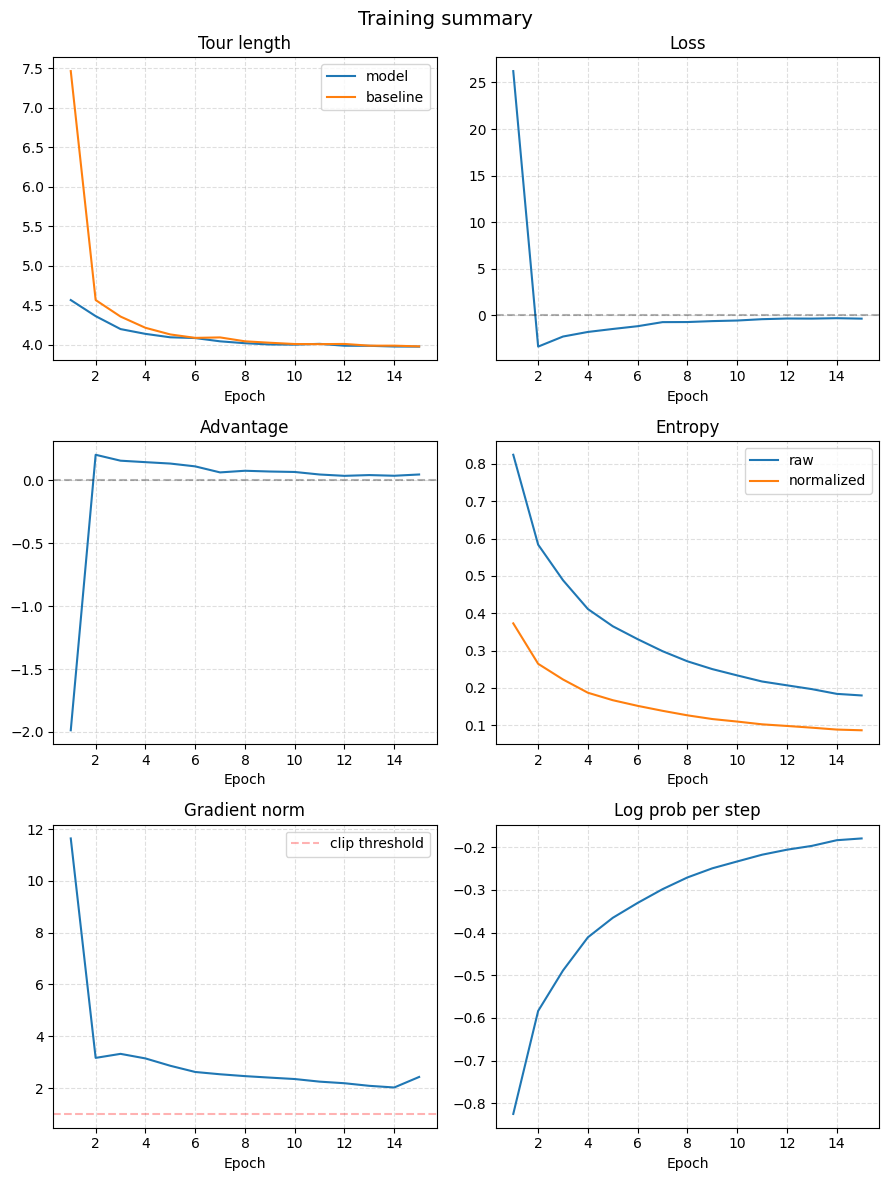

In [65]:
def plot_epoch_summaries(summaries: list[EpochSummary]) -> None:
    epochs = [s.epoch for s in summaries]
    updates = [s.epoch for s in summaries if s.baseline_updated]

    fig, axes = plt.subplots(3, 2, figsize=(9, 12))
    fig.suptitle("Training summary", fontsize=14)

    def add_baseline_updates(ax):
        for e in updates:
            ax.axvline(e, color="red", linestyle="--", alpha=0.3, linewidth=1)

    # -- tour length --
    ax = axes[0, 0]
    ax.plot(epochs, [s.obj_model for s in summaries], label="model")
    ax.plot(epochs, [s.obj_baseline for s in summaries], label="baseline")
    # add_baseline_updates(ax)
    ax.set_title("Tour length")
    ax.legend()

    # -- loss --
    ax = axes[0, 1]
    ax.plot(epochs, [s.loss for s in summaries])
    # add_baseline_updates(ax)
    ax.set_title("Loss")
    ax.axhline(0, color="black", linestyle="--", alpha=0.3)

    # -- advantage --
    ax = axes[1, 0]
    ax.plot(epochs, [s.advantage for s in summaries])
    # add_baseline_updates(ax)
    ax.axhline(0, color="black", linestyle="--", alpha=0.3)
    ax.set_title("Advantage")

    # -- entropy --
    ax = axes[1, 1]
    ax.plot(epochs, [s.entropy for s in summaries], label="raw")
    ax.plot(epochs, [s.entropy_norm for s in summaries], label="normalized")
    # add_baseline_updates(ax)
    ax.set_title("Entropy")
    ax.legend()

    # -- grad norm --
    ax = axes[2, 0]
    ax.plot(epochs, [s.grad_norm for s in summaries])
    # add_baseline_updates(ax)
    ax.set_title("Gradient norm")
    ax.axhline(1.0, color="red", linestyle="--", alpha=0.3, label="clip threshold")
    ax.legend()

    # -- log prob per step --
    ax = axes[2, 1]
    ax.plot(epochs, [s.log_p for s in summaries])
    # add_baseline_updates(ax)
    ax.set_title("Log prob per step")

    for ax in axes.flat:
        ax.set_xlabel("Epoch")
        ax.grid(True, linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()


plot_epoch_summaries(epoch_summaries)

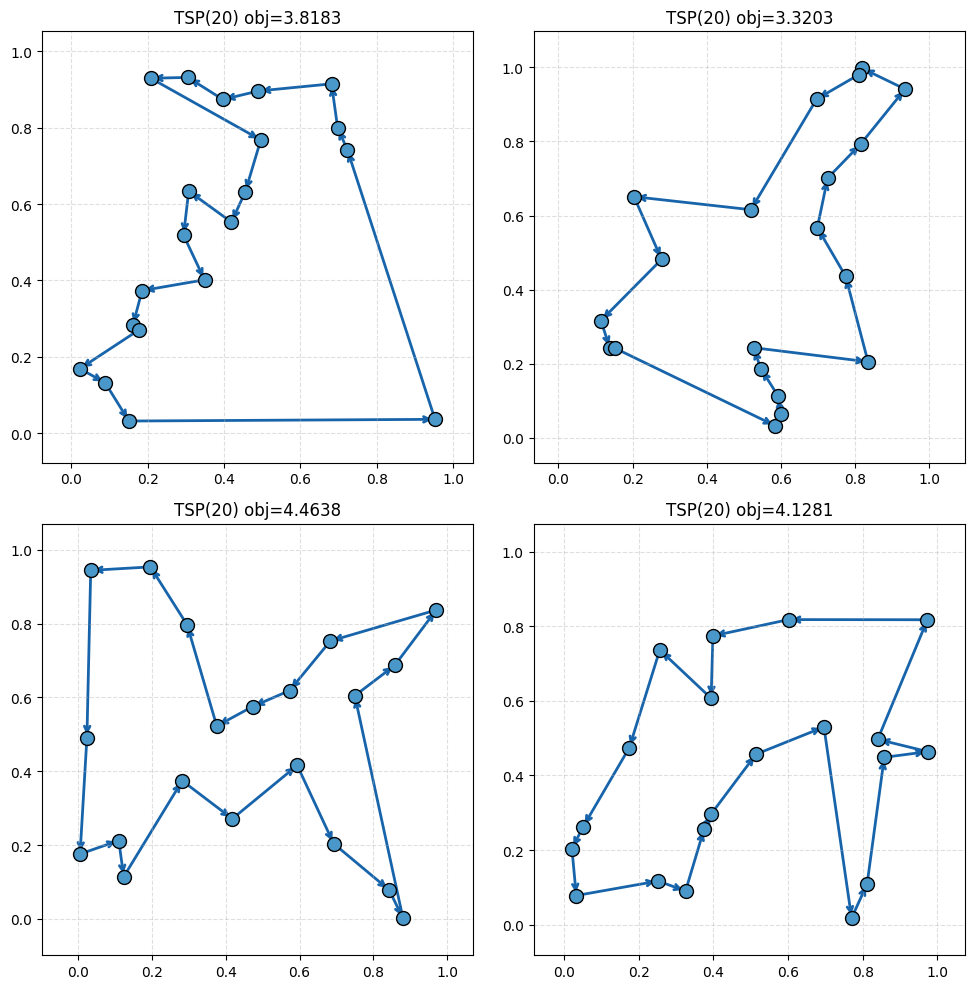

In [63]:
from core.problems.tsp.solution import TSPSolution

test_sampler = TSPBatchSampler(
    TSPConfig(
        num_locations=20,
        min_coordinate=0.0,
        max_coordinate=1.0,
        distribution_of_locations="uniform",
    ),
    seed=0,
)

instances = test_sampler(4).to(DEVICE)

rollout = model(instances, greedy=True)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    solution = TSPSolution(
        instance=TSPInstance.from_tensor(instances[i]),
        tour=rollout.tour[i],
    )
    solution.visualize(ax=ax)

plt.tight_layout()
plt.show()